In [23]:
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from time import time
from torchvision import datasets, transforms
from torch import nn, optim

In [24]:
transform = transforms.ToTensor()

trainset = datasets.MNIST('./MNIST_data/', download=True, train=True, transform=transform) #Carrega a parte do treino do dataset
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True) #Cria um buffer para pegar os dados por partes 

valset = datasets.MNIST('./MNIST_data', download=True, train=False, transform=transform) #Carrega a parte de valçidação
valloader = torch.utils.data.DataLoader(valset, batch_size=64, shuffle=True) #Cria um buffer para pegar pos dados por partes

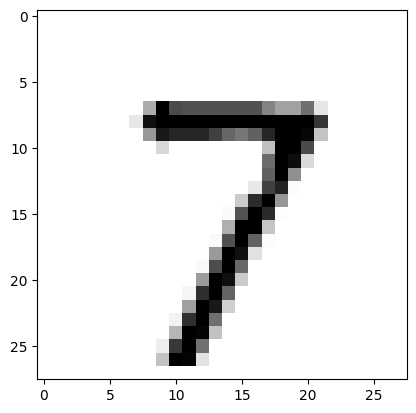

In [25]:
dataiter = iter(trainloader)
imagens, etiquetas = next(dataiter)
plt.imshow(imagens[0].numpy().squeeze(), cmap='gray_r')
plt.show()

In [26]:
print(imagens[0].shape) #Para verificar as dimensoes do tensor de cada imagem
print(etiquetas[0].shape) #Para verificar as dimensoes do tensor de cada etiqueta

torch.Size([1, 28, 28])
torch.Size([])


In [27]:
class Modelo(nn.Module):
    def __init__(self):
        super(Modelo, self).__init__()
        self.linear1 = nn.Linear(28*28, 128) # CAMADA DE ENTRADA, 784 neurônios que se ligam a 128
        self.linear2 = nn.Linear(128, 64)    # CAMADA INTERNA1, 128 neurônios que se ligam a 64
        self.linear3 = nn.Linear(64, 10)     # CAMADA INTERNA2, 64 neurônios que se ligam a 10
        # A CAMADA DE SAÍDA  NÃO É NECESSARIO DEFINIR NADA POIS SÓ PRECISAMOS PEGAR O OUTPUT DA CAMADA INTERNA
    
    def forward(self,X):
        X = F.relu(self.linear1(X))          # função de ativação da camada de entrada para a camada interna1
        X = F.relu(self.linear2(X))          # função de ativação da camada interna1 para a camda interna2
        X = self.linear3(X)                  # função de ativação da camada interna2 para a camada de saída, nesse caso f(x) = x
        return F.log_softmax(X, dim=1)       #dados utilizados para calcular a perda

In [28]:
def treino(modelo, trainloader, device):
    otimizador = optim.SGD(modelo.parameters(), lr=0.01, momentum=0.5)  # define a política de atualização dos pesos
    inicio = time()  # timer para sabermos quanto tempo levou o treino

    criterio = nn.NLLLoss()  # definindo o critério para calcular a perda
    EPOCHS = 10  # número de epochs que o algoritmo rodará
    modelo.train()  # ativando o modo de treinamento do modelo

    for epoch in range(EPOCHS):
        perda_acumulada = 0  # inicialização da perda acumulada da epoch em questão

        for imagens, etiquetas in trainloader:
            imagens = imagens.view(imagens.shape[0], -1)  # convertendo as imagens para "vetores" de 28*28 casas
            otimizador.zero_grad()  # zerando os gradientes por conta do ciclo anterior

            output = modelo(imagens.to(device))  # colocando os dados no modelo
            perda_instantanea = criterio(output, etiquetas.to(device))  # calculando a perda da epoch em questão

            perda_instantanea.backward()  # backpropagation a partir da perda
            otimizador.step()  # atualizando os pesos e o bias

            perda_acumulada += perda_instantanea.item()  # atualização da perda acumulada

        else:
            print("Epoch {} - Perda resultante: {}".format(epoch+1, perda_acumulada / len(trainloader)))

    print("\nTempo de treino (em minutos) =", (time() - inicio) / 60)

In [29]:
def validacao(modelo, valloader, device):
    conta_corretas, conta_todas = 0, 0
    for imagens, etiquetas in valloader:
        for i in range(len(etiquetas)):
            img = imagens[i].view(1, 784)  # redimensiona a imagem para vetor 1x784

            # desativar o autograd para acelerar a validação. Grafos computacionais dinâmicos têm um custo alto de processamento
            with torch.no_grad():
                logps = modelo(img.to(device))  # output do modelo em escala logarítmica

            ps = torch.exp(logps)  # converte output para escala normal (lembre que é um tensor)
            probab = list(ps.cpu().numpy())[0]
            etiqueta_pred = np.argmax(probab)  # converte o tensor em número, no caso, o número que o modelo previu
            etiqueta_certa = etiquetas.numpy()[i]

            if etiqueta_certa == etiqueta_pred:  # compara a previsão com o valor correto
                conta_corretas += 1
            conta_todas += 1

    print("Total de imagens testadas =", conta_todas)
    print("\nPrecisão do modelo = {}%".format(conta_corretas * 100 / conta_todas))

In [30]:
modelo = Modelo()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
modelo.to(device)

Modelo(
  (linear1): Linear(in_features=784, out_features=128, bias=True)
  (linear2): Linear(in_features=128, out_features=64, bias=True)
  (linear3): Linear(in_features=64, out_features=10, bias=True)
)

In [31]:
treino(modelo, trainloader, device)
validacao(modelo, valloader, device)

Epoch 1 - Perda resultante: 1.2199768433248057
Epoch 2 - Perda resultante: 0.39615369994820815
Epoch 3 - Perda resultante: 0.3190840026145297
Epoch 4 - Perda resultante: 0.27590482684372586
Epoch 5 - Perda resultante: 0.24213065954048368
Epoch 6 - Perda resultante: 0.21613112964164982
Epoch 7 - Perda resultante: 0.19403089585104413
Epoch 8 - Perda resultante: 0.17636690592206616
Epoch 9 - Perda resultante: 0.16054534668059173
Epoch 10 - Perda resultante: 0.1476998939446962

Tempo de treino (em minutos) = 1.0173150181770325
Total de imagens testadas = 10000

Precisão do modelo = 95.69%
